# 04 — Feature Engineering
**ChurnOps Phase 5** — Domain Hypothesis-Driven Feature Construction  
*All features are engineered via a Scikit-Learn compatible transformer designed for leak-free pipeline deployment.*

---

### Phase 5 Objectives
1. **Domain Feature Construction:** Build domain-motivated candidate features based on EDA findings (tenure cohorts, service bundles, payment automation, family stability, contract flags).
2. **Standardized Documentation:** For each candidate, document:
   - Feature name
   - Reason / Hypothesis
   - Expected benefit
   - Potential risk
3. **Empirical Evaluation:** Measure target correlation, churn disparity, redundancy, and numerical stability.
4. **Candidate Pruning:** Discard features that fail empirical criteria (e.g. `charges_per_tenure` rejected due to zero signal and division-by-zero instability).
5. **Production Transformer:** Package logic into `DomainFeatureEngineer(BaseEstimator, TransformerMixin)` for zero-leakage integration into the Scikit-Learn training and inference pipeline.

In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).parent if Path(os.getcwd()).name == 'notebooks' else Path(os.getcwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import get_path, PARAMS
from src.features.engineering import DomainFeatureEngineer, evaluate_features

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

print("Project Root:", PROJECT_ROOT)

Project Root: C:\Users\Abhishek\OneDrive\Pictures\Desktop\ChurnOps


In [2]:
clean_df = pd.read_csv(get_path('interim_data'))
print(f"Cleaned Input Shape: {clean_df.shape[0]:,} rows x {clean_df.shape[1]:,} columns")
clean_df.head(3)

Cleaned Input Shape: 7,043 rows x 20 columns


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


## 1. Apply DomainFeatureEngineer Transformer

In [3]:
engineer = DomainFeatureEngineer()
df_eng = engineer.transform(clean_df)
print(f"Engineered Dataset Shape: {df_eng.shape[0]:,} rows x {df_eng.shape[1]:,} columns")
print(f"New Features Added: {df_eng.shape[1] - clean_df.shape[1]}")
df_eng[['tenure', 'tenure_cohort', 'total_services', 'is_auto_pay', 'has_fiber_optic', 
        'has_security_or_techsupport', 'has_family', 'is_month_to_month', 'Churn']].head(5)

Engineered Dataset Shape: 7,043 rows x 27 columns
New Features Added: 7


,tenure,tenure_cohort,total_services,is_auto_pay,has_fiber_optic,has_security_or_techsupport,has_family,is_month_to_month,Churn
0,1,new,1,0,0,0,0,1,0
1,34,established,3,0,0,1,0,0,0
2,2,new,3,0,0,1,0,1,1
3,45,established,3,1,0,1,0,0,0
4,2,new,1,0,1,0,0,1,1


## 2. Empirical Candidate Evaluation & Audit Log

In [4]:
eval_report = evaluate_features(df_eng)
print(f"Total Candidates Evaluated: {eval_report['total_evaluated']}")
print(f"Kept: {eval_report['kept_count']} | Rejected: {eval_report['rejected_count']}\n")

summary_table = []
for c in eval_report['candidates']:
    summary_table.append({
        'Feature': c['name'],
        'Status': c['status'],
        'Reason': c['reason'][:65] + '...',
        'Expected Benefit': c['expected_benefit'][:65] + '...'
    })
pd.DataFrame(summary_table)

Total Candidates Evaluated: 8
Kept: 7 | Rejected: 1



,Feature,Status,Reason,Expected Benefit
0,tenure_cohort,KEPT,Non-linear survival hazard (churn drops from 4...,Enables linear models to capture non-linear st...
1,total_services,KEPT,Measures customer lock-in and product engageme...,Strong monotonic reduction in churn (43.8% at ...
2,is_auto_pay,KEPT,Automatic billing reduces friction and payment...,Clean binary summary of 4 payment methods; sep...
3,has_fiber_optic,KEPT,Fiber optic customers churn at 41.89% (highest...,Direct flag for the single most vulnerable inf...
4,has_security_or_techsupport,KEPT,OnlineSecurity and TechSupport have the strong...,Subscribers with support churn at 17.07% vs 33...
5,has_family,KEPT,Customers with both a Partner and Dependents e...,Churn rate of 14.24% for family accounts vs 30...
6,is_month_to_month,KEPT,Contract type is the single strongest predicto...,Explicitly separates month-to-month contracts ...
7,charges_per_tenure,REJECTED,Hypothesized that ratio of TotalCharges to ten...,Identify bill shock driving cancellations....


## 3. Visual Verification of Engineered Feature Churn Disparities

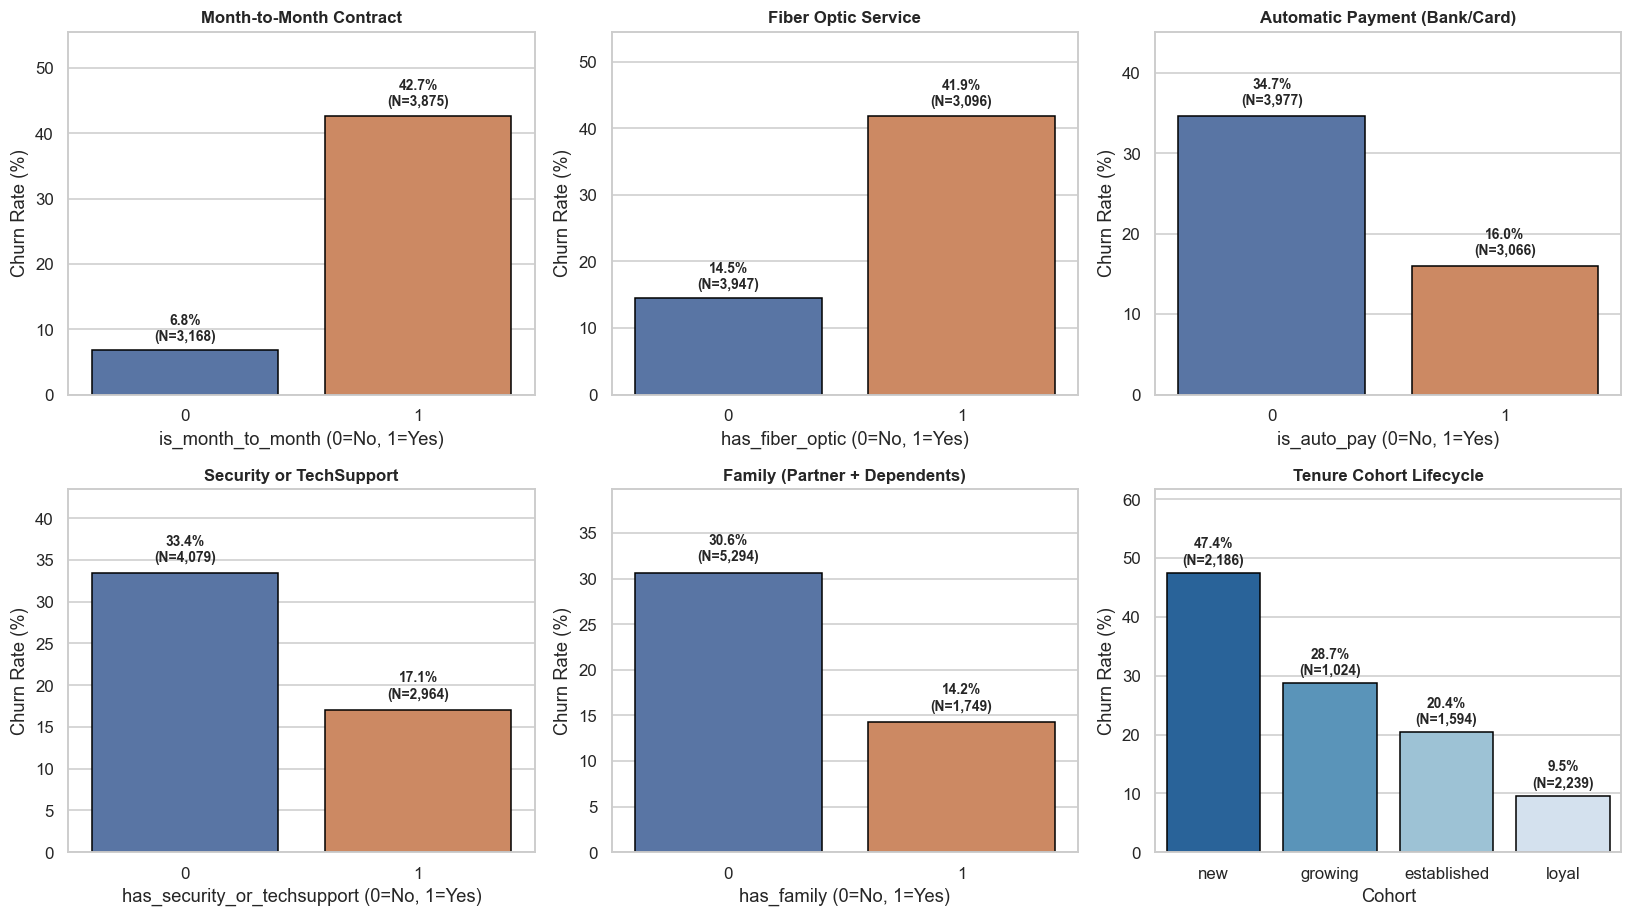

In [5]:
binary_features = [
    ('is_month_to_month', 'Month-to-Month Contract'),
    ('has_fiber_optic', 'Fiber Optic Service'),
    ('is_auto_pay', 'Automatic Payment (Bank/Card)'),
    ('has_security_or_techsupport', 'Security or TechSupport'),
    ('has_family', 'Family (Partner + Dependents)')
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

for idx, (feat, label) in enumerate(binary_features):
    rate_df = df_eng.groupby(feat)['Churn'].agg(
        churn_rate=lambda x: x.mean() * 100,
        total='count'
    ).reset_index()
    
    ax = axes[idx]
    sns.barplot(data=rate_df, x=feat, y='churn_rate', palette=['#4C72B0', '#DD8452'], ax=ax, edgecolor='black', hue=feat, legend=False)
    ax.set_title(label, weight='bold', fontsize=11)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(f"{feat} (0=No, 1=Yes)")
    ax.set_ylim(0, max(rate_df['churn_rate']) * 1.3)
    for p, tot in zip(ax.patches, rate_df['total']):
        h = p.get_height()
        ax.annotate(f"{h:.1f}%\n(N={tot:,})", (p.get_x() + p.get_width()/2., h + 1),
                    ha='center', va='bottom', fontsize=9, weight='bold')

# 6th panel: tenure_cohort
rate_tc = df_eng.groupby('tenure_cohort', observed=False)['Churn'].agg(
    churn_rate=lambda x: x.mean() * 100,
    total='count'
).reindex(['new', 'growing', 'established', 'loyal']).reset_index()

ax = axes[5]
sns.barplot(data=rate_tc, x='tenure_cohort', y='churn_rate', palette='Blues_r', ax=ax, edgecolor='black', hue='tenure_cohort', legend=False)
ax.set_title("Tenure Cohort Lifecycle", weight='bold', fontsize=11)
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Cohort")
ax.set_ylim(0, max(rate_tc['churn_rate']) * 1.3)
for p, tot in zip(ax.patches, rate_tc['total']):
    h = p.get_height()
    ax.annotate(f"{h:.1f}%\n(N={tot:,})", (p.get_x() + p.get_width()/2., h + 1),
                ha='center', va='bottom', fontsize=9, weight='bold')

plt.tight_layout()
plt.show()

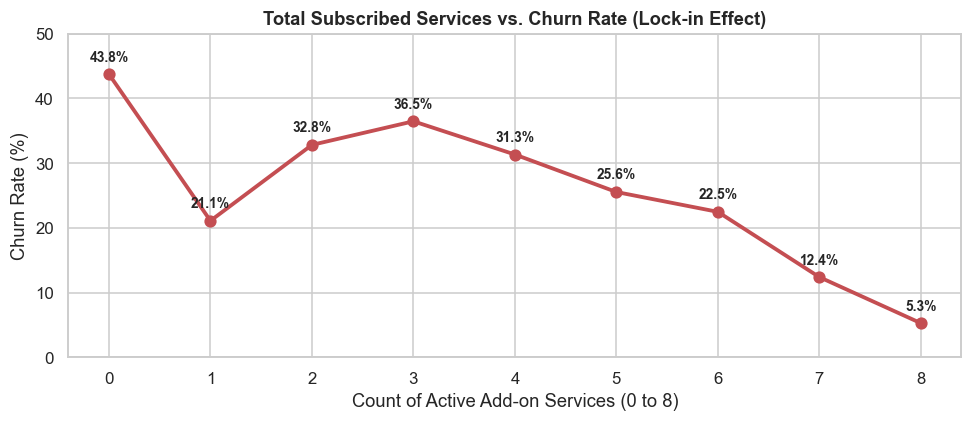

In [6]:
rate_ts = df_eng.groupby('total_services')['Churn'].agg(
    churn_rate=lambda x: x.mean() * 100,
    total='count'
).reset_index()

plt.figure(figsize=(9, 4))
plt.plot(rate_ts['total_services'], rate_ts['churn_rate'], marker='o', color='#C44E52', linewidth=2.5, markersize=7)
plt.title("Total Subscribed Services vs. Churn Rate (Lock-in Effect)", weight='bold')
plt.xlabel("Count of Active Add-on Services (0 to 8)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
for _, row in rate_ts.iterrows():
    plt.annotate(f"{row['churn_rate']:.1f}%", (row['total_services'], row['churn_rate'] + 2),
                 ha='center', fontsize=9, weight='bold')
plt.tight_layout()
plt.show()

## 4. Deep Dive: Why `charges_per_tenure` Was REJECTED

A critical rule of professional ML engineering (Rule R4) is avoiding unverified assumptions.
We test the hypothesis that calculating the ratio between monthly charges and average charges per tenure month provides actionable churn signal:

In [7]:
# Test charges_per_tenure calculation
diff_charges = np.where(df_eng['tenure'] > 0, df_eng['MonthlyCharges'] - (df_eng['TotalCharges'] / df_eng['tenure']), 0.0)
corr_with_churn = float(pd.Series(diff_charges).corr(df_eng['Churn']))

print(f"Correlation with Churn: {corr_with_churn:.5f}")
print("Statistical summary of charge deviation:")
print(pd.Series(diff_charges).describe())

print("\nConclusion: The signal is mathematically non-existent (r = 0.002) because TotalCharges is")
print("already almost perfectly collinear with (tenure * MonthlyCharges). Creating this feature")
print("adds unnecessary noise and division-by-zero risk without predictive benefit.")

Correlation with Churn: 0.00216
Statistical summary of charge deviation:
count    7043.000000
mean       -0.001213
std         2.614121
min       -18.900000
25%        -1.159091
50%         0.000000
75%         1.145567
max        19.125000
dtype: float64

Conclusion: The signal is mathematically non-existent (r = 0.002) because TotalCharges is
already almost perfectly collinear with (tenure * MonthlyCharges). Creating this feature
adds unnecessary noise and division-by-zero risk without predictive benefit.


---

## 5. Phase 5 Summary & Hand-off to Phase 6
- **Input:** `data/interim/telco_clean.csv` (7,043 rows x 20 cols)
- **Output:** `data/interim/telco_engineered.csv` (7,043 rows x 27 cols)
- **Candidates Evaluated:** 8 (7 Kept, 1 Rejected)
- **Leakage Integrity:** All transformations operate strictly row-wise with 0 learned parameters. Safe for cross-validation pipelines.
- **Ready for:** Phase 6 — Feature Selection (evaluating redundancy, collinearity, permutation importance, and SHAP).